Bai 1

K tối ưu (với metric='minkowski', p=2): K = 1, Accuracy = 0.9667


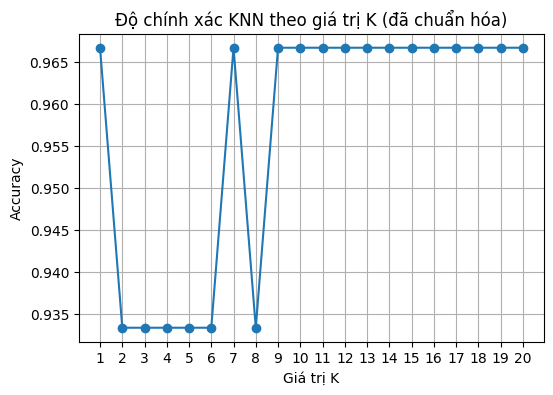


=== So sánh các độ đo khoảng cách ===
Euclidean (minkowski, p=2)   -> Accuracy: 0.9667
Manhattan (p=1)              -> Accuracy: 0.9667
Minkowski (p=3)              -> Accuracy: 0.9667


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Tải dữ liệu Iris và chia tập train/test
iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Chuẩn hóa dữ liệu đầu vào
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Tìm giá trị K tối ưu
k_values = range(1, 21)
acc_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=2)
    knn.fit(X_train_scaled, y_train)
    pred = knn.predict(X_test_scaled)
    acc_scores.append(accuracy_score(y_test, pred))

best_k = k_values[np.argmax(acc_scores)]
print(f"K tối ưu (với metric='minkowski', p=2): K = {best_k}, Accuracy = {max(acc_scores):.4f}")

# Biểu đồ độ chính xác theo K
plt.figure(figsize=(6, 4))
plt.plot(k_values, acc_scores, marker='o')
plt.xticks(k_values)
plt.xlabel("Giá trị K")
plt.ylabel("Accuracy")
plt.title("Độ chính xác KNN theo giá trị K (đã chuẩn hóa)")
plt.grid(True)
plt.show()

# 3. Thực nghiệm các khoảng cách khác nhau với K tối ưu
metrics_list = [
    ("Euclidean (minkowski, p=2)", {"metric": "minkowski", "p": 2}),
    ("Manhattan (p=1)", {"metric": "manhattan"}),
    ("Minkowski (p=3)", {"metric": "minkowski", "p": 3}),
]

print("\n=== So sánh các độ đo khoảng cách ===")
for name, params in metrics_list:
    clf = KNeighborsClassifier(n_neighbors=best_k, **params)
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    print(f"{name:28s} -> Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Bai 2

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải dữ liệu Boston Housing
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
try:
    df = pd.read_csv(url)
    X = df.drop(columns=["medv"])
    y = df["medv"]
except Exception:
    from sklearn.datasets import make_regression
    X, y = make_regression(n_samples=506, n_features=13, noise=4.5, random_state=42)

# 2. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Chuẩn hóa đặc trưng
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Áp dụng KNN Regressor với K = 3, 5, 7, 9
print("=== Kết quả KNN Regressor trên Boston Housing ===")
for k in [3, 5, 7, 9]:
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_train_sc, y_train)
    y_pred = knn_reg.predict(X_test_sc)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"K = {k} | MSE = {mse:.4f} | R2 Score = {r2:.4f}")

=== Kết quả KNN Regressor trên Boston Housing ===
K = 3 | MSE = 19.4043 | R2 Score = 0.7354
K = 5 | MSE = 20.6055 | R2 Score = 0.7190
K = 7 | MSE = 23.4155 | R2 Score = 0.6807
K = 9 | MSE = 24.0094 | R2 Score = 0.6726


Bai 3

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

splits = [
    ("Chia 80/20 (random_state=42)", 0.2, 42, None),
    ("Chia 70/30 (random_state=42)", 0.3, 42, None),
    ("Chia 80/20 Stratified (giữ tỷ lệ lớp)", 0.2, 42, y),
]

for desc, test_sz, seed, strat in splits:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_sz, random_state=seed, stratify=strat
    )
    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    svm_clf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
    svm_clf.fit(X_tr_sc, y_tr)
    y_pred = svm_clf.predict(X_te_sc)

    print(f"\n--- {desc} ---")
    print(f"Accuracy: {accuracy_score(y_te, y_pred):.4f}")
    print(classification_report(y_te, y_pred, target_names=iris.target_names, zero_division=0))


--- Chia 80/20 (random_state=42) ---
Accuracy: 1.0000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


--- Chia 70/30 (random_state=42) ---
Accuracy: 1.0000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


--- Chia 80/20 Stratified (giữ tỷ lệ lớp) ---
Accuracy: 0.9667
              precision    recall  f1-score   support

      set

Bai 4

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
try:
    df = pd.read_csv(url)
    X = df.drop(columns=["medv"])
    y = df["medv"]
except Exception:
    from sklearn.datasets import make_regression
    X, y = make_regression(n_samples=506, n_features=13, noise=4.5, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print("=== So sánh SVR với kernel 'linear' và 'rbf' ===")
for kernel_type in ['linear', 'rbf']:
    svr_model = SVR(kernel=kernel_type, C=10.0)
    svr_model.fit(X_train_sc, y_train)
    y_pred = svr_model.predict(X_test_sc)
    print(f"Kernel = '{kernel_type:6s}' | MSE = {mean_squared_error(y_test, y_pred):.4f} | R2 = {r2_score(y_test, y_pred):.4f}")

=== So sánh SVR với kernel 'linear' và 'rbf' ===
Kernel = 'linear' | MSE = 28.7853 | R2 = 0.6075
Kernel = 'rbf   ' | MSE = 12.7382 | R2 = 0.8263


BTVN 1

In [5]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

cancer = datasets.load_breast_cancer()
X, y = cancer.data, cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

kernels = ['linear', 'poly', 'rbf', 'sigmoid']
print("=== Đánh giá SVM theo từng loại Kernel (Breast Cancer) ===")
for k in kernels:
    clf = SVC(kernel=k, C=1.0, gamma='scale', random_state=42)
    clf.fit(X_train_sc, y_train)
    pred = clf.predict(X_test_sc)
    print(f"Kernel = {k:8s} | Accuracy = {accuracy_score(y_test, pred):.4f} | F1-score = {f1_score(y_test, pred):.4f}")

=== Đánh giá SVM theo từng loại Kernel (Breast Cancer) ===
Kernel = linear   | Accuracy = 0.9737 | F1-score = 0.9790
Kernel = poly     | Accuracy = 0.9123 | F1-score = 0.9351
Kernel = rbf      | Accuracy = 0.9825 | F1-score = 0.9861
Kernel = sigmoid  | Accuracy = 0.9298 | F1-score = 0.9437


2

In [6]:
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

cancer = datasets.load_breast_cancer()
X, y = cancer.data, cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}

grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_sc, y_train)

print("Bộ siêu tham số tối ưu:", grid.best_params_)
print(f"Độ chính xác trung bình Cross-Validation: {grid.best_score_:.4f}")

best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_test_sc)
print(f"Độ chính xác trên tập Test: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Bộ siêu tham số tối ưu: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Độ chính xác trung bình Cross-Validation: 0.9802
Độ chính xác trên tập Test: 0.9825
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



3

KNN (K=5)              -> Accuracy: 0.9639
SVM (kernel='poly')    -> Accuracy: 0.9722
SVM (kernel='rbf')     -> Accuracy: 0.9806


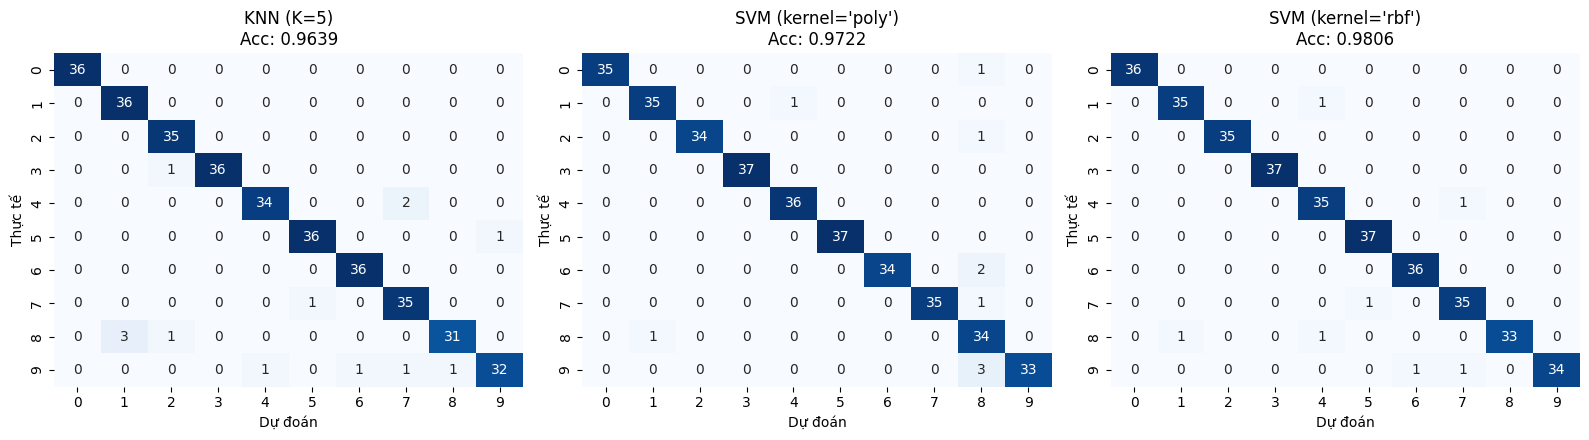

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# Tải dữ liệu Digits
digits = load_digits()
X, y = digits.data, digits.target

# Chuẩn hóa và chia tập train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Huấn luyện KNN và SVM (poly, rbf)
models = {
    "KNN (K=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (kernel='poly')": SVC(kernel='poly', degree=3, C=1.0, random_state=42),
    "SVM (kernel='rbf')": SVC(kernel='rbf', C=5.0, gamma='scale', random_state=42),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_test_sc)
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    print(f"{name:22s} -> Accuracy: {acc:.4f}")

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f"{name}\nAcc: {acc:.4f}")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")

plt.tight_layout()
plt.show()